In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [19]:
# Load Boston Housing Dataset
boston = fetch_openml(name="boston", version=1, as_frame=True)

X = boston.data
y = boston.target

# Convert data into numeric format
X = X.apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(y, errors="coerce")

print("Dataset loaded successfully!")
print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])

Dataset loaded successfully!
Number of rows: 506
Number of features: 13


In [20]:
# Display first five rows
X.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33


In [21]:
# Check for duplicate rows
print("Number of duplicate rows:", X.duplicated().sum())

# Remove duplicate rows
duplicate_rows = X.duplicated()

X = X.loc[~duplicate_rows].reset_index(drop=True)
y = y.loc[~duplicate_rows].reset_index(drop=True)

print("Shape after removing duplicates:", X.shape)

Number of duplicate rows: 0
Shape after removing duplicates: (506, 13)


In [22]:
# Check missing values
print("Missing values in each column:")
print(X.isnull().sum())

Missing values in each column:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
dtype: int64


In [23]:
# Replace missing values with median
imputer = SimpleImputer(strategy="median")

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

# Remove rows where target value is missing
valid_rows = y.notna()

X = X.loc[valid_rows].reset_index(drop=True)
y = y.loc[valid_rows].reset_index(drop=True)

print("Total missing values after handling:", X.isnull().sum().sum())

Total missing values after handling: 0


In [ ]:
# Check correlation between features
correlation_matrix = X.corr()

print("Correlation matrix:")
display(correlation_matrix.round(2))

# Display highly correlated feature pairs (absolute correlation >= 0.80)
high_correlation = (
    correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    .stack()
    .sort_values(key=np.abs, ascending=False)
)

print("\nHighly correlated feature pairs (|correlation| >= 0.80):")
print(high_correlation[high_correlation.abs() >= 0.80])

# Visualize the correlation matrix
plt.figure(figsize=(10, 8))
plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=90)
plt.yticks(range(len(correlation_matrix.columns)), correlation_matrix.columns)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [24]:
# Detect outliers using IQR method

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Count outliers
outliers = ((X < lower_limit) | (X > upper_limit)).sum()

print("Number of outliers in each feature:")
print(outliers)

print("\nTotal number of outliers:", outliers.sum())

Number of outliers in each feature:
CRIM       66
ZN         68
INDUS       0
CHAS       35
NOX         0
RM         30
AGE         0
DIS         5
RAD         0
TAX         0
PTRATIO    15
B          77
LSTAT       7
dtype: int64

Total number of outliers: 303


In [ ]:
# Box plot before IQR capping
plt.figure(figsize=(14, 7))
X.boxplot(rot=45)
plt.title("Box Plot Before IQR Outlier Handling")
plt.ylabel("Feature values")
plt.tight_layout()
plt.show()

In [25]:
# Handle outliers using IQR capping
# No rows are removed

X = X.clip(
    lower=lower_limit,
    upper=upper_limit,
    axis=1
)

print("Outliers have been handled using IQR capping.")
print("No rows have been removed.")
print("Dataset shape:", X.shape)

# Verify that no values remain outside the IQR limits
remaining_outliers = ((X < lower_limit) | (X > upper_limit)).sum()
print("Remaining outliers after capping:", remaining_outliers.sum())

Outliers have been handled using IQR capping.
No rows have been removed.
Dataset shape: (506, 13)


In [ ]:
# Box plot after IQR capping
plt.figure(figsize=(14, 7))
X.boxplot(rot=45)
plt.title("Box Plot After IQR Outlier Handling")
plt.ylabel("Feature values")
plt.tight_layout()
plt.show()

In [26]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (404, 13)
Testing data: (102, 13)


In [27]:
# Create Linear Regression model

model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [28]:
# Predict house prices

y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print(y_pred[:10])

Predictions generated successfully!
[29.80438349 33.50092271 15.26310545 25.33334589 18.67758112 23.53970987
 17.65206963 14.06138567 23.27519488 21.02939555]


In [29]:
# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("----- Model Evaluation -----")
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

----- Model Evaluation -----
Mean Absolute Error (MAE): 3.2168940668083907
Mean Squared Error (MSE): 23.335132651412394
Root Mean Squared Error (RMSE): 4.83064515892157
R2 Score: 0.6817955975297644


In [30]:
# Compare actual and predicted values

results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

results.head(10)

,Actual Price,Predicted Price
0,23.6,29.804383
1,32.4,33.500923
2,13.6,15.263105
3,22.8,25.333346
4,16.1,18.677581
5,20.0,23.539710
6,17.8,17.652070
7,14.0,14.061386
8,19.6,23.275195
9,16.8,21.029396


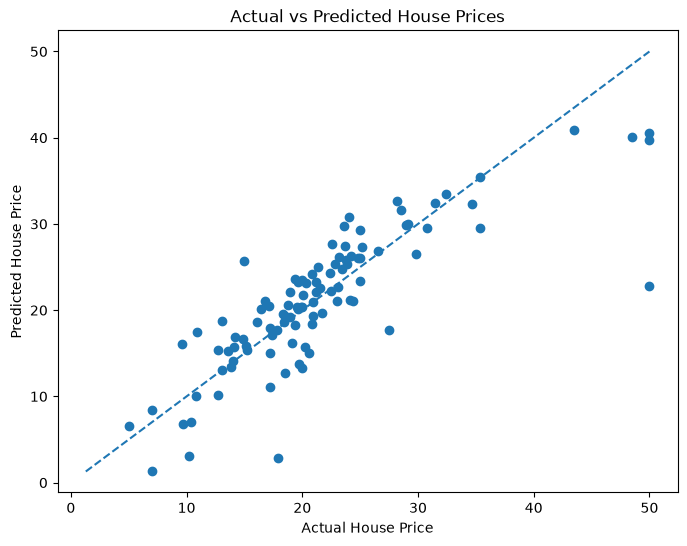

In [31]:
# Plot Actual vs Predicted values

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")

# Perfect prediction line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.show()

In [32]:
# Display coefficients of each feature

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients

,Feature,Coefficient
0,CRIM,-5.775478e-01
1,ZN,1.877761e-02
2,INDUS,5.480844e-02
3,CHAS,5.422052e-14
4,NOX,-1.465869e+01
5,RM,4.816312e+00
6,AGE,-3.764830e-03
7,DIS,-1.364820e+00
8,RAD,3.395727e-01
9,TAX,-1.002960e-02


In [33]:
print("Model Intercept:", model.intercept_)

Model Intercept: 26.164940498219593


In [34]:
print("Linear Regression successfully implemented.")
print("The Boston Housing dataset was cleaned,")
print("missing values and outliers were handled,")
print("the data was divided into training and testing sets,")
print("and a Linear Regression model was trained and evaluated.")

Linear Regression successfully implemented.
The Boston Housing dataset was cleaned,
missing values and outliers were handled,
the data was divided into training and testing sets,
and a Linear Regression model was trained and evaluated.
